In [1]:
from google.colab import files

uploaded = files.upload()

Saving Iris.csv to Iris.csv


In [2]:
import pandas as pd

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("File uploaded:", filename)
print("\nDataset:")
display(df.head())

print("\nShape:", df.shape)
print("\nColumns:")
print(df.columns)

File uploaded: Iris.csv

Dataset:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa



Shape: (150, 6)

Columns:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

print(df.head())
print("\nShape of dataset:", df.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Shape of dataset: (150, 4)


In [5]:
X = df

print("Features used for clustering:")
print(X.head())

Features used for clustering:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans

kmeans_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(n_clusters=3, random_state=42, n_init=10))
])

# Train the model
kmeans_pipeline.fit(X)

# Get cluster labels
kmeans_labels = kmeans_pipeline.predict(X)

print("K-Means Cluster Labels:")
print(kmeans_labels)

K-Means Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


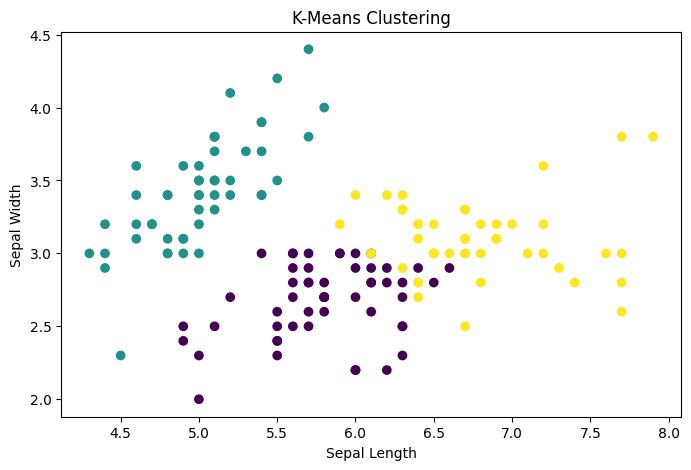

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=kmeans_labels,
    cmap='viridis'
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("K-Means Clustering")

plt.show()

In [9]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('hierarchical', AgglomerativeClustering(n_clusters=3))
])

# Train model and predict clusters
hierarchical_labels = hierarchical_pipeline.fit_predict(X)

print("Hierarchical Cluster Labels:")
print(hierarchical_labels)

Hierarchical Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


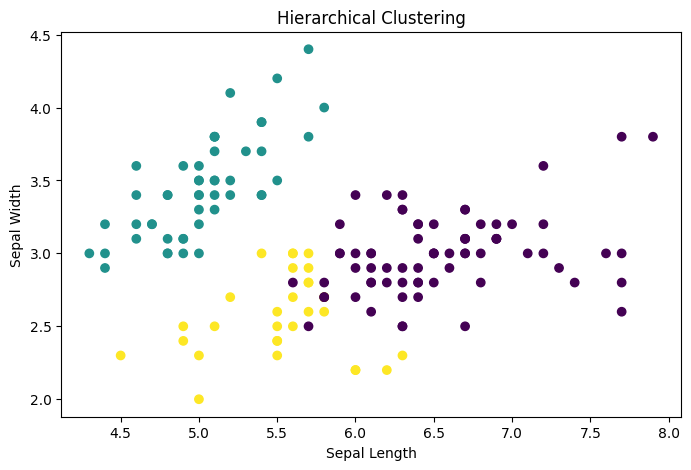

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=hierarchical_labels,
    cmap='viridis'
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Hierarchical Clustering")

plt.show()

In [11]:
from sklearn.cluster import DBSCAN

dbscan_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('dbscan', DBSCAN(eps=0.8, min_samples=5))
])

# Train model
dbscan_labels = dbscan_pipeline.fit_predict(X)

print("DBSCAN Cluster Labels:")
print(dbscan_labels)

DBSCAN Cluster Labels:
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1 -1  1  1
  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]


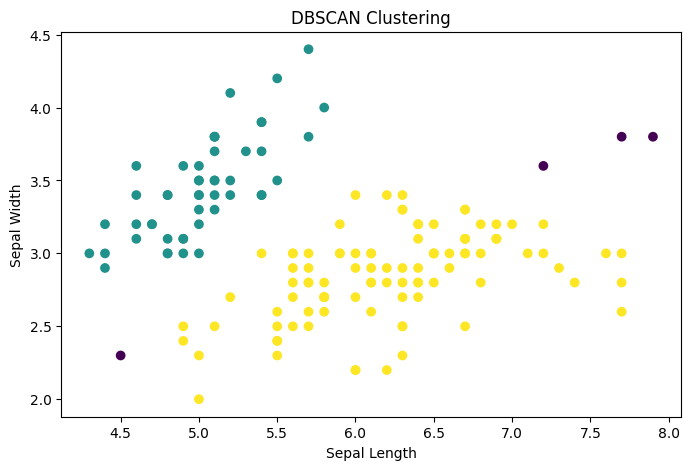

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=dbscan_labels,
    cmap='viridis'
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("DBSCAN Clustering")

plt.show()

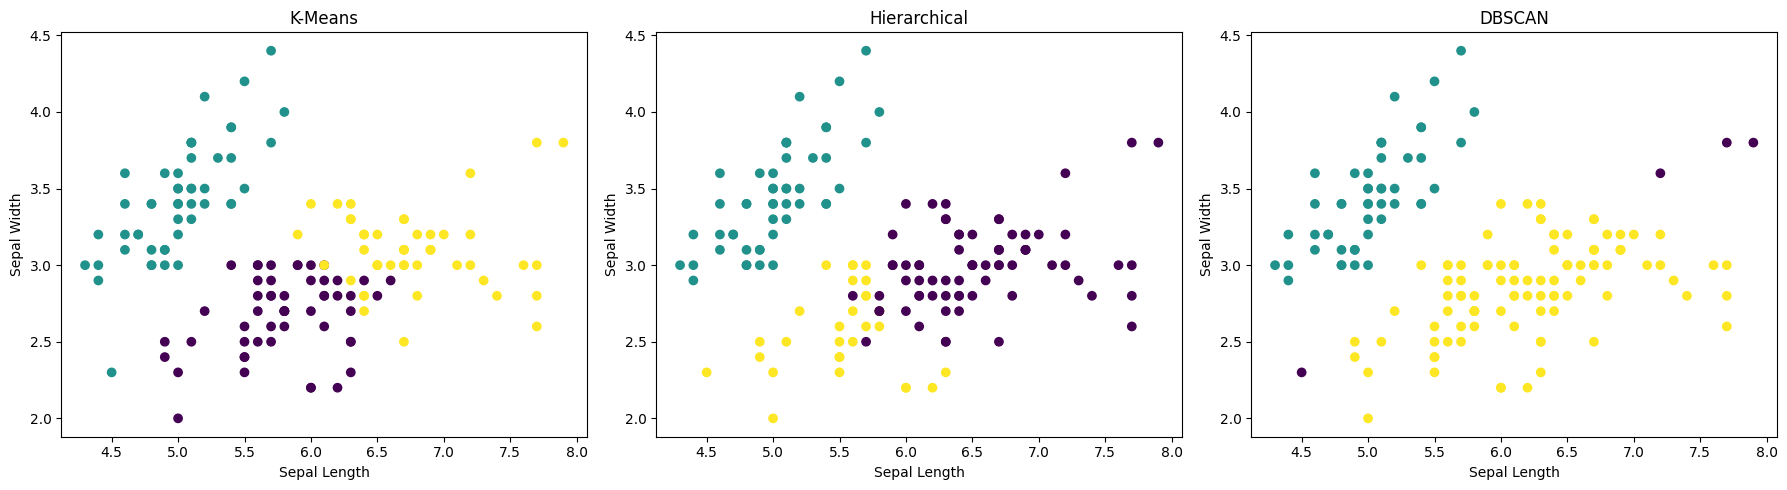

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# K-Means
axes[0].scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=kmeans_labels,
    cmap='viridis'
)
axes[0].set_title("K-Means")
axes[0].set_xlabel("Sepal Length")
axes[0].set_ylabel("Sepal Width")

# Hierarchical
axes[1].scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=hierarchical_labels,
    cmap='viridis'
)
axes[1].set_title("Hierarchical")
axes[1].set_xlabel("Sepal Length")
axes[1].set_ylabel("Sepal Width")

# DBSCAN
axes[2].scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=dbscan_labels,
    cmap='viridis'
)
axes[2].set_title("DBSCAN")
axes[2].set_xlabel("Sepal Length")
axes[2].set_ylabel("Sepal Width")

plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import silhouette_score

# K-Means
kmeans_score = silhouette_score(X_scaled, kmeans_labels)

# Hierarchical
hierarchical_score = silhouette_score(X_scaled, hierarchical_labels)

# DBSCAN
# DBSCAN must have at least 2 clusters
if len(set(dbscan_labels)) > 1:
    dbscan_score = silhouette_score(X_scaled, dbscan_labels)
else:
    dbscan_score = "Not applicable"

print("Silhouette Scores:")
print("K-Means:", kmeans_score)
print("Hierarchical:", hierarchical_score)
print("DBSCAN:", dbscan_score)

Silhouette Scores:
K-Means: 0.45994823920518635
Hierarchical: 0.4466890410285909
DBSCAN: 0.5216965052515835
